# Recognising daily activities from a wrist sensor

A wrist accelerometer records 24 hours of movement. Can we tell what its wearer was doing in every 10 seconds? It is hard because the recordings are of people's normal, unscripted days, and the labels come from camera photos taken every 20-40 seconds.

This notebook classifies 10 activities on CAPTURE-24 (151 participants; Chan et al., *Scientific Data* 2024, doi:10.1038/s41597-024-03960-3). Model A is a random forest on hand-made features of each 10 s window. Model B adds a hidden Markov model (HMM) that smooths A's output over time.

- **Reproduction.** Window counts match the paper's exactly. A rerun of its random forest + HMM from the authors' code scores κ 0.660 on the 51 held-out participants (95% interval 0.630 to 0.692), against a published 0.637.
- **Two pitfalls, measured.** Splitting sequences where annotation stops leaks 0.02 macro-F1. With too few trees, imblearn's balanced forest gives 29% of sleep and sitting windows no out-of-bag output (section 4 has the rule); they become rows of zeros, which costs an HMM fitted on that output 0.075 κ.
- **A small gain.** B is 0.039 κ above the rerun on the same five cross-validation folds (standard error 0.013, over folds that share participants). On the held-out participants the difference is +0.029 κ (95% interval 0.001 to 0.058, paired by participant), consistent with a small gain of about 0.03 κ, and at most about 0.06. Macro-F1 does not differ reliably on either. B uses 300 trees against the rerun's 3,000.
- **Caveat.** B's held-out macro-F1, 0.566, leans on sports, which only 8 of those participants did; its cross-validation macro-F1 is 0.522. The paper's deep model is above B on κ (0.735); its macro-F1, 0.576, is inside B's interval (0.524 to 0.595). B's holdout has been scored twice, once with an earlier version (section 3).

![Held-out scores against the paper's models](outputs/results.png)

*Held-out macro-F1 and κ with 95% intervals (Figure 4 below).*

Macro-F1 is the average score per activity, so rare activities count as much as sleep. κ (Cohen's kappa) is agreement with the labels beyond what chance would give.

## Setup

Imports and configuration. A run takes about 7 min on 8 logical cores once both caches in `data/` exist. The first run also builds the feature cache (about 9 min) and the rerun of the paper's pipeline (about 18 min).

In [1]:
import json
import sys
import warnings
import zipfile
from pathlib import Path
from time import perf_counter

import joblib
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from joblib import Parallel, delayed
from sklearn.ensemble._forest import _generate_unsampled_indices
from sklearn.metrics import confusion_matrix
from sklearn.model_selection import StratifiedGroupKFold

sys.path.insert(0, "scripts")
import features as F
import har
from har import BLUE, CLASSES, CODES, INK, ORANGE, SHOWN, draw_band, fit_hmm, metrics_from_cm, participant_cms, smooth

Settings, paths and the paper's published numbers. `har.CODES` is alphabetical, so a tied label vote resolves as pandas' `mode()` does in the paper's `prepare_data.py`.

In [2]:
T0 = perf_counter()
SEED = 42
N_FOLDS = 5
N_BOOT = 2000
N_TREES = 300
PAPER_VERSION = 1  # bump when paper_pipeline changes; it is part of the cache file name
PAPER_TREES, PAPER_BATCH = 3000, 600  # the paper's forest, fitted in batches to fit in memory
LOAD_JOBS = 4  # each worker holds about 1 GB

DATA, OUT = Path("data"), Path("outputs")
RAW = DATA / "capture24"
CACHE = DATA / f"features_w{F.WINSEC}s_v{F.FEATURE_VERSION}.parquet"
STATS_CACHE = DATA / f"participant_stats_w{F.WINSEC}s_v{F.FEATURE_VERSION}.parquet"
PAPER_CACHE = DATA / f"paper_copy_v{PAPER_VERSION}_w{F.WINSEC}s_v{F.FEATURE_VERSION}_trees{PAPER_TREES}_seed{SEED}_folds{N_FOLDS}.joblib"

SCHEME = "WillettsSpecific2018"  # the paper's 10 activities
DEV_IDS = [f"P{i:03d}" for i in range(1, 101)]  # P101-P151 is the holdout
PAPER_WINDOWS = {"all": 922_199, "P001-P100": 618_129, "P101-P151": 304_070}
PAPER = {"Paper RF": (0.388, 0.514), "Paper RF + HMM": (0.486, 0.637), "Paper CNN + HMM": (0.576, 0.735)}  # (macro-F1, kappa)

har.set_style()
OUT.mkdir(exist_ok=True)

## 1. Data

`capture24.zip` (CC BY 4.0, <https://doi.org/10.5287/bodleian:NGx0JOMP5>) goes in `data/`. It holds one CSV per participant (100 Hz, in g, with an annotation per sample) and two metadata files.

In [3]:
if not RAW.exists():
    zipfile.ZipFile(DATA / "capture24.zip").extractall(DATA)
FILES = sorted(RAW.glob("P[0-9][0-9][0-9].csv.gz"))
print(len(FILES), "participant files;", "other files:", sorted(p.name for p in RAW.iterdir() if p not in FILES))
pd.read_csv(FILES[0], nrows=3)

151 participant files; other files: ['annotation-label-dictionary.csv', 'metadata.csv']


,time,x,y,z,annotation
0,2016-11-13 02:18:00.000000,-0.46669,-0.533341,0.658472,7030 sleeping;MET 0.95
1,2016-11-13 02:18:00.010000,-0.46669,-0.533341,0.658472,7030 sleeping;MET 0.95
2,2016-11-13 02:18:00.020000,-0.46669,-0.533341,0.658472,7030 sleeping;MET 0.95


Each recording is cut into 10 s windows and reduced to 39 features on its own, in parallel, so the 100 Hz signal is never held in memory at once. The window table is cached in `data/`, with a few statistics per participant.

In [4]:
def load_label_codes():
    labels = pd.read_csv(RAW / "annotation-label-dictionary.csv", index_col="annotation", dtype="string")[f"label:{SCHEME}"]
    assert set(labels) == set(CLASSES), sorted(set(labels))
    return labels.map(CODES.index).astype(int)


def process_participant(path, label_codes):
    raw = F.load_participant(path)
    time, xyz = raw["time"].to_numpy(), raw[["x", "y", "z"]].to_numpy()
    annotation = raw["annotation"].cat  # codes: annotation id per sample, -1 where unlabelled
    class_of = {"10-class": label_codes[annotation.categories].to_numpy()}
    X, start, y, _ = F.make_windows(time, xyz, annotation.codes.to_numpy(), class_of)
    pid = path.name[:4]
    table = pd.concat([pd.DataFrame({"participant": pid, "window_start": start, **y}), F.extract_features(X)], axis=1)
    stats = {"participant": pid, "hours": len(raw) / F.SAMPLE_RATE / 3600,
             "nan_share": np.isnan(xyz).any(axis=1).mean(), "unlabelled_share": raw["annotation"].isna().mean(),
             "steps_over_1s": int((np.diff(time) >= np.timedelta64(1, "s")).sum())}
    return table, stats


def load_windows():
    if not (CACHE.exists() and STATS_CACHE.exists()):
        warnings.filterwarnings("ignore", message="A worker stopped")  # loky recycles workers as memory grows
        codes = load_label_codes()
        results = Parallel(n_jobs=LOAD_JOBS)(delayed(process_participant)(p, codes) for p in FILES)
        pd.concat([r[0] for r in results], ignore_index=True).to_parquet(CACHE)
        pd.DataFrame([r[1] for r in results]).to_parquet(STATS_CACHE)
    return pd.read_parquet(CACHE), pd.read_parquet(STATS_CACHE).set_index("participant")

In [5]:
windows, stats = load_windows()
LABELLED = windows["10-class"].to_numpy() >= 0
IS_DEV = windows["participant"].isin(DEV_IDS).to_numpy()
print(f"{len(stats)} participants, {stats['hours'].min():.0f} to {stats['hours'].max():.0f} h each, "
      f"{(stats['nan_share'] > 0).sum()} with missing samples, "
      f"{(stats['steps_over_1s'] > 0).sum()} with a recording gap over 1 s, "
      f"{stats['unlabelled_share'].mean():.0%} of samples unlabelled")

151 participants, 13 to 32 h each, 0 with missing samples, 8 with a recording gap over 1 s, 34% of samples unlabelled


Window rule: 10 s bins from each participant's first sample; drop a bin if it has fewer than 1,000 samples or any NaN; label it with the most frequent class among its labelled samples, so a bin whose label changes partway is kept. A bin with "unlabelled" as its most frequent annotation stays unlabelled: the HMM decodes it, and it is never trained on, scored or counted below. The current `prepare_data.py` labels any bin with one labelled sample, which gives 934,762 windows (+1.4%); leaving out the unlabelled-majority bins matches the paper's counts exactly.

**Table 1.** Labelled windows per split, against the paper's counts.

In [6]:
def window_counts():
    ours = {"all": int(LABELLED.sum()), "P001-P100": int((LABELLED & IS_DEV).sum()), "P101-P151": int((LABELLED & ~IS_DEV).sum())}
    table = pd.DataFrame({"ours": ours, "paper": PAPER_WINDOWS})
    table["diff %"] = (100 * (table["ours"] / table["paper"] - 1)).round(3)
    return table


COUNTS = window_counts()
COUNTS

,ours,paper,diff %
all,922199,922199,0.0
P001-P100,618129,618129,0.0
P101-P151,304070,304070,0.0


**Figure 1.** One participant's day: the mean vector magnitude per second, with the 10 activity labels underneath.

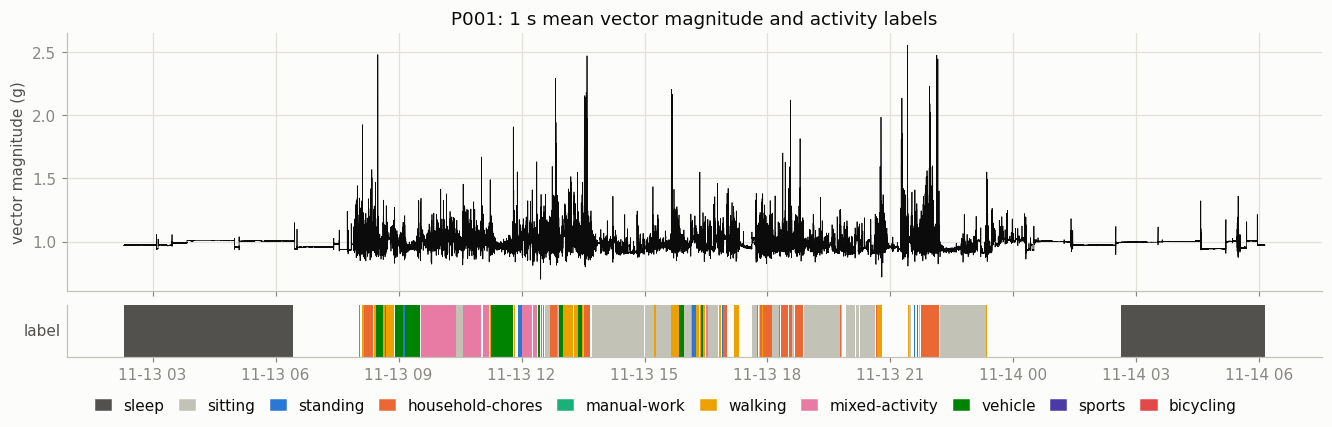

In [7]:
def plot_day(pid="P001"):
    raw = F.load_participant(RAW / f"{pid}.csv.gz")
    magnitude = pd.Series(np.linalg.norm(raw[["x", "y", "z"]].to_numpy(), axis=1), index=raw["time"]).resample("1s").mean()
    w = windows[windows["participant"] == pid]
    fig, (ax, band) = plt.subplots(2, 1, sharex=True, figsize=(12, 3.8), height_ratios=[5, 1], layout="constrained")
    ax.plot(magnitude.index, magnitude.to_numpy(), lw=0.5, color=INK)
    ax.set(ylabel="vector magnitude (g)", title=f"{pid}: 1 s mean vector magnitude and activity labels")
    draw_band(band, w["window_start"].to_numpy(), w["10-class"].to_numpy(), "label")
    har.class_legend(fig)


plot_day()

**Figure 2.** How often each activity occurs among the labelled windows of the development participants (P001-P100) and the held-out ones (P101-P151).

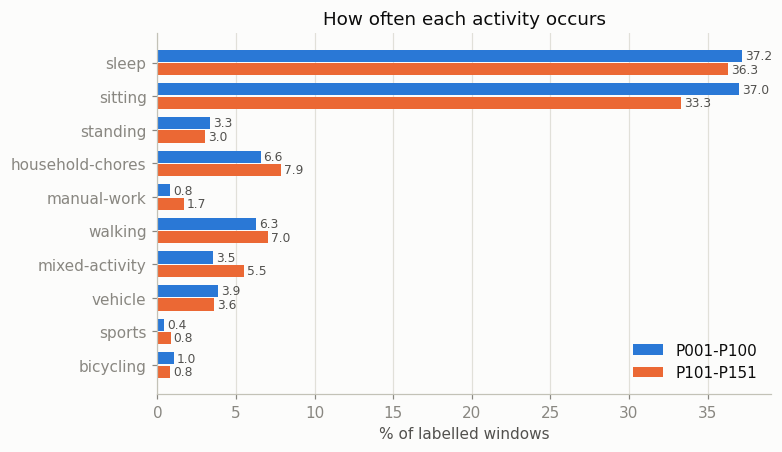

In [8]:
def plot_class_share():
    order = [CODES.index(n) for n in CLASSES]
    labels = windows["10-class"].to_numpy()

    def share(mask):
        return 100 * np.bincount(labels[mask & LABELLED], minlength=len(CLASSES))[order] / (mask & LABELLED).sum()

    _, ax = plt.subplots(figsize=(7, 4), layout="constrained")
    y = np.arange(len(CLASSES))
    for offset, mask, label, color in ((-0.2, IS_DEV, "P001-P100", BLUE), (0.2, ~IS_DEV, "P101-P151", ORANGE)):
        bars = ax.barh(y + offset, share(mask), height=0.36, color=color, label=label)
        ax.bar_label(bars, fmt="%.1f", padding=2, fontsize=8, color="#52514e")
    ax.set(yticks=y, yticklabels=CLASSES, xlabel="% of labelled windows", title="How often each activity occurs")
    ax.invert_yaxis()
    ax.grid(axis="y", visible=False)
    ax.legend()


plot_class_share()

## 2. Models

### 2.1 Model A: features and a random forest

Each window becomes 39 numbers computed in `scripts/features.py`. Most describe how strongly and how regularly the wrist moved: moments, quantiles, autocorrelation, spectrum and peaks of the acceleration magnitude, following the capture24 [feature list](https://github.com/OxWearables/capture24/blob/master/feature-list.md) without its third dominant frequency. Nine describe how the wrist was oriented: per-axis means and stds and correlations between axes. The model sees nothing else: no participant id, demographics or time of day.

A is imblearn's `BalancedRandomForestClassifier` with 300 trees (the paper's has 3,000); each tree trains on a sample with equally many windows of every activity. It is scored two ways: 5-fold cross-validation (CV) on P001-P100 with each participant in one fold only, and one fit on P001-P100 scored on P101-P151, the paper's holdout. The holdout fit comes last, under Results.

In [9]:
X = windows[F.FEATURE_NAMES].to_numpy()
Y = windows["10-class"].to_numpy()  # -1 = unlabelled
GROUPS = windows["participant"].to_numpy()
DEV, TEST = np.flatnonzero(IS_DEV), np.flatnonzero(~IS_DEV)
ALL_FEATURES = slice(None)


def fit_forest(rows, cols=ALL_FEATURES, **kwargs):
    return har.balanced_forest(N_TREES, SEED, **kwargs).fit(X[rows][:, cols], Y[rows])


def fit_split(train, test):
    forest = fit_forest(train[Y[train] >= 0])
    return {"train": train, "test": test, "proba": forest.predict_proba(X[test])}

Five participant-grouped folds over P001-P100, stratified on the labelled windows, and one forest per fold. Each fold holds every window of its participants, labelled or not.

In [10]:
FOLDS = har.participant_folds(Y, GROUPS, np.flatnonzero(IS_DEV & LABELLED), N_FOLDS, SEED)
CV_SPLITS = [fit_split(train, valid) for train, valid in FOLDS]

### 2.2 Model B: smoothing over time

A judges each window alone, so its output flickers. People do not change activity every 10 seconds, and an HMM uses that: it knows how often each activity occurs and that an activity usually continues, so it holds the current one until A's output argues against it strongly and for long enough. Its transition matrix is close to never switching, because the labels almost never show one activity directly after another; part 2 (`capture24_new_model.ipynb`) shows why: annotators leave a gap at almost every change of activity.

The prior and transition matrix come from the training participants of each fit. The emission likelihood is the forest's probability vector, which is approximately proportional to P(window | activity) because each tree trains on a class-balanced sample; only approximately, since a forest's probabilities are not calibrated. B decodes every window of a recording, labelled or not, since a deployed model is not told where the annotation gaps are; only labelled windows are scored. The HMM code (Viterbi decoding and fitting) is in `scripts/har.py`.

In [11]:
# A sequence breaks only where the recording does: all windows are kept, labelled or not.
SEQ = har.sequence_ids(windows["window_start"].to_numpy(), GROUPS)


def decode(split):
    train, test = split["train"], split["test"]
    hmm = fit_hmm(Y[train], SEQ[train], len(CODES))
    return smooth(split["proba"], SEQ[test], hmm)[Y[test] >= 0]


def predict(split):
    train, test = split["train"], split["test"]
    scored = Y[test] >= 0
    majority = np.bincount(Y[train][Y[train] >= 0]).argmax()
    return test[scored], {"Dummy": np.full(scored.sum(), majority), "A": split["proba"][scored].argmax(axis=1), "B": decode(split)}

Each fold's labelled validation windows, with three predictions for them: the most common training activity (a dummy, for scale), A and B.

In [12]:
CV_PRED = [predict(split) for split in CV_SPLITS]

### 2.3 The paper's pipeline as a baseline

For a like-for-like bar, the paper's random forest + HMM is rerun here on the same folds and the same holdout. Its configuration was fixed from the paper's code (`rf.py`, `classifier.py`, `hmm.py`) before any score was seen, and it was run once:

- the forest is imblearn's balanced random forest with 3,000 trees, on the 30 features that do not describe orientation;
- the HMM sees only the forest's top class, through an emission matrix averaged from the forest's out-of-bag output; it has a uniform prior and decodes labelled windows only, as one sequence per participant. That protocol knows at test time which windows have labels, a mild form of the annotation-gap leak measured below; on these folds it does not help.

Three things differ from the paper's own run. The features are this notebook's code and cover 30 of the paper's 32 (no third dominant frequency or its power). The 3,000 trees are fitted as five forests of 600 with different seeds, so that they fit in 16 GB of memory. And the paper's code can load tuned forest settings that its repo does not include, so the defaults are used. Scoring this baseline on the holdout selects nothing for B.

`decode_with` is B's decoding with the paper's three HMM choices exposed, so the ablation below can swap them one at a time.

In [13]:
PAPER_FEATURES = [i for i, name in enumerate(F.FEATURE_NAMES) if not name.startswith(("x_", "y_", "z_", "corr_"))]
PARTICIPANT_SEQ = pd.factorize(GROUPS)[0]


def matrix_lik(output, truth, proba):
    """The paper's emission model: the HMM sees only the forest's top class. emit[true class] is the mean of `output`
    (forest output for training windows) over that class, as in hmm.py."""
    emit = np.stack([output[truth == c].mean(axis=0) for c in range(output.shape[1])])
    return emit[:, proba.argmax(axis=1)].T


def decode_with(split, lik, seq=SEQ, labelled_only=False, uniform_prior=False):
    train, test = split["train"], split["test"]
    scored = Y[test] >= 0
    if labelled_only:
        train, test, lik, scored = train[Y[train] >= 0], test[scored], lik[scored], scored[scored]
    hmm = fit_hmm(Y[train], seq[train], lik.shape[1])
    if uniform_prior:
        hmm["prior"] = np.full(lik.shape[1], 1 / lik.shape[1])
    return smooth(lik, seq[test], hmm)[scored]

The paper fits its emission matrix on the forest's out-of-bag output. `oob_sums` recomputes that output tree by tree, so the windows that get none can be counted, and `expected_uncovered` predicts their share from the class sizes alone.

In [14]:
def oob_sums(forest, features):
    """Sum of out-of-bag tree probabilities, and number of out-of-bag trees, per training window. imblearn's rule:
    a window is out-of-bag for a tree if it is in that tree's undersampled pool and the tree's bootstrap missed it."""
    total, count = np.zeros((len(features), forest.n_classes_)), np.zeros(len(features))
    for sampler, tree in zip(forest.samplers_, forest.estimators_):
        pool = sampler.sample_indices_
        out = pool[_generate_unsampled_indices(tree.random_state, len(pool), len(pool))]
        total[out] += tree.predict_proba(features[out])
        count[out] += 1
    return total, count


def uncovered_share(count, truth):
    return np.bincount(truth, weights=count == 0) / np.bincount(truth)


def expected_uncovered(truth, trees):
    """Share of each class's windows expected to get no out-of-bag output. A window is in a tree's pool with
    probability about 1 - exp(-smallest class / its class), and the bootstrap then misses it with probability 1/e."""
    n = np.bincount(truth)
    return (1 - (1 - np.exp(-n.min() / n)) / np.e) ** trees

The whole pipeline, run on each CV fold and then on the holdout. Each run takes minutes, so each is cached as it finishes.

In [15]:
def paper_pipeline(train, test):
    """The paper's RF + HMM as classifier.py and hmm.py have it -> predictions for the labelled windows of `test`,
    and the share of training windows per class without out-of-bag output."""
    labelled, scored = train[Y[train] >= 0], test[Y[test] >= 0]
    features, total, count, proba = X[labelled][:, PAPER_FEATURES], 0, 0, 0
    for batch in range(PAPER_TREES // PAPER_BATCH):
        forest = fit_forest(labelled, PAPER_FEATURES, n_estimators=PAPER_BATCH, random_state=SEED + batch)
        sums = oob_sums(forest, features)
        total, count = total + sums[0], count + sums[1]
        proba = proba + forest.predict_proba(X[scored][:, PAPER_FEATURES])
    oob = total / np.maximum(count, 1)[:, None]  # like imblearn, a window without out-of-bag output keeps a row of zeros
    pred = decode_with({"train": train, "test": scored}, matrix_lik(oob, Y[labelled], proba),
                       PARTICIPANT_SEQ, labelled_only=True, uniform_prior=True)
    return pred, uncovered_share(count, Y[labelled])


def paper_copy():
    splits = [(split["train"], split["test"]) for split in CV_SPLITS] + [(DEV, TEST)]
    done = joblib.load(PAPER_CACHE) if PAPER_CACHE.exists() else []
    for train, test in splits[len(done):]:
        done.append(paper_pipeline(train, test))
        joblib.dump(done, PAPER_CACHE)
    return done[:-1], done[-1]

## 3. Results

Macro-F1 and κ come from a confusion matrix. Holdout intervals are 95% percentile bootstraps over participants (2,000 draws), because windows from one person are correlated. Cross-validation spreads and standard errors are over the five folds; the folds share most of their training participants, so those understate the uncertainty, and the paired holdout bootstrap is the inference to lean on. The paper says only "bootstrapping (n=100)"; its repo's `eval.py` resamples participants.

The holdout models are fitted here, after everything above was settled. B's holdout has been scored twice: once with an earlier version of B, and once here. Every change in between was chosen on CV. For scale, predicting the most common activity for every window scores macro-F1 0.05.

In [16]:
HOLDOUT = fit_split(DEV, TEST)
SCORED = TEST[LABELLED[TEST]]
PRED = predict(HOLDOUT)[1]
PAPER_CV, PAPER_HOLDOUT = paper_copy()

**Figure 3.** Six hours of one held-out participant: the camera labels, A and B. Only labelled windows are drawn, so blank stretches have no camera label.

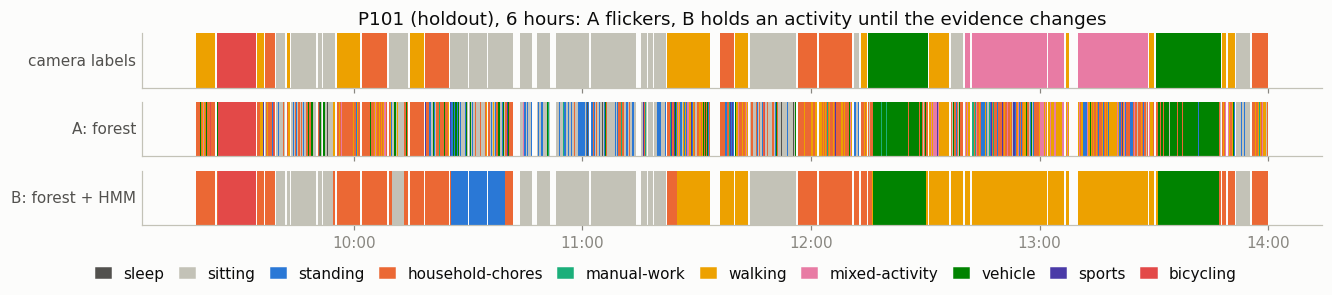

In [17]:
def plot_bands(pid="P101", first_hour=8, hours=6):
    start = windows["window_start"].to_numpy()[SCORED]
    begin = start[GROUPS[SCORED] == pid].min().astype("datetime64[D]") + np.timedelta64(first_hour, "h")
    shown = (GROUPS[SCORED] == pid) & (start >= begin) & (start < begin + np.timedelta64(hours, "h"))
    bands = {"camera labels": Y[SCORED], "A: forest": PRED["A"], "B: forest + HMM": PRED["B"]}
    fig, axes = plt.subplots(3, 1, sharex=True, figsize=(12, 2.6), layout="constrained")
    for ax, (name, codes) in zip(axes, bands.items()):
        draw_band(ax, start[shown], codes[shown], name)
    axes[0].set_title(f"{pid} (holdout), {hours} hours: A flickers, B holds an activity until the evidence changes")
    axes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))
    har.class_legend(fig)
    fig.savefig(OUT / "bands.png", dpi=150)


plot_bands()

The excerpt is the first holdout participant, 08:00 to 14:00 on their first day (their labels start at about 09:20), picked by position alone. B removes A's flicker and gets the long sitting and vehicle spells right. It also turns both long mixed-activity spells into walking, an error Figure 5 shows in general: 43% of held-out mixed-activity windows become walking.

Scores come from confusion matrices: one per fold in CV, and one per held-out participant, so that participants can be resampled for the intervals.

In [18]:
def confusion(rows, pred):
    return confusion_matrix(Y[rows], pred, labels=range(len(CODES)))


def holdout_cms(pred):
    return participant_cms(Y[SCORED], pred, GROUPS[SCORED], len(CODES))


def score_holdout(pred):
    cms = holdout_cms(pred)
    point, boots = metrics_from_cm(cms.sum(axis=0)), har.bootstrap_metrics(cms, N_BOOT, SEED)
    return {**{m: har.interval(point[m], boots[m]) for m in SHOWN},
            "per_class_f1": dict(zip(CODES, point["per_class_f1"])), "cm": cms.sum(axis=0)}

In [19]:
CV_CM = {model: [confusion(rows, preds[model]) for rows, preds in CV_PRED] for model in ("Dummy", "A", "B")}
CV = pd.DataFrame([{"model": model, "fold": fold, **metrics_from_cm(cm)} for model, cms in CV_CM.items() for fold, cm in enumerate(cms)]
                  ).groupby("model")[list(SHOWN)].agg(["mean", "std"])
SCORES = {model: score_holdout(pred) for model, pred in PRED.items()}
COPY_CV = pd.DataFrame([metrics_from_cm(confusion(rows, pred)) for (rows, _), (pred, _) in zip(CV_PRED, PAPER_CV)])[list(SHOWN)]
COPY = score_holdout(PAPER_HOLDOUT[0])
GAIN = har.paired_gain(holdout_cms(PRED["B"]), holdout_cms(PAPER_HOLDOUT[0]), SHOWN, N_BOOT, SEED)
print("holdout, B minus the rerun of the paper's pipeline, paired by participant:",
      "; ".join(f"{name} {GAIN[m]['value']:+.3f} [{GAIN[m]['ci'][0]:+.3f}, {GAIN[m]['ci'][1]:+.3f}]" for m, name in SHOWN.items()))

holdout, B minus the rerun of the paper's pipeline, paired by participant: macro-F1 +0.031 [-0.011, +0.080]; κ +0.029 [+0.001, +0.058]


**Table 2.** Cross-validation (mean ± standard deviation over the five folds) and holdout [95% interval], next to the paper's published holdout numbers.

In [20]:
def results_table():
    scored = {"A: random forest": (CV.loc["A"], SCORES["A"]),
              "B: A + HMM": (CV.loc["B"], SCORES["B"]),
              "Paper's RF + HMM, rerun here": (COPY_CV.agg(["mean", "std"]).unstack(), COPY)}
    rows = {}
    for label, (cv, holdout) in scored.items():
        rows[label] = {}
        for m, name in SHOWN.items():
            h = holdout[m]
            rows[label][f"{name} CV"] = f"{cv[m, 'mean']:.3f} ± {cv[m, 'std']:.3f}"
            rows[label][f"{name} holdout"] = f"{h['value']:.3f} [{h['ci'][0]:.3f}, {h['ci'][1]:.3f}]"
    for model, numbers in PAPER.items():
        rows[f"{model}, published"] = {f"{name} holdout": f"{n:.3f}" for name, n in zip(SHOWN.values(), numbers)}
    return pd.DataFrame(rows).T.fillna("")


results_table()

,macro-F1 CV,macro-F1 holdout,κ CV,κ holdout
A: random forest,0.406 ± 0.017,"0.415 [0.380, 0.438]",0.535 ± 0.014,"0.530 [0.503, 0.555]"
B: A + HMM,0.522 ± 0.033,"0.566 [0.524, 0.595]",0.708 ± 0.025,"0.690 [0.653, 0.725]"
"Paper's RF + HMM, rerun here",0.517 ± 0.041,"0.535 [0.490, 0.566]",0.670 ± 0.030,"0.660 [0.630, 0.692]"
"Paper RF, published",,0.388,,0.514
"Paper RF + HMM, published",,0.486,,0.637
"Paper CNN + HMM, published",,0.576,,0.735


**Figure 4.** Held-out macro-F1 and κ with 95% intervals. Diamonds are the cross-validation means; grey bars are the paper's published numbers. B's held-out macro-F1 leans on sports, which only 8 participants did (Table 3).

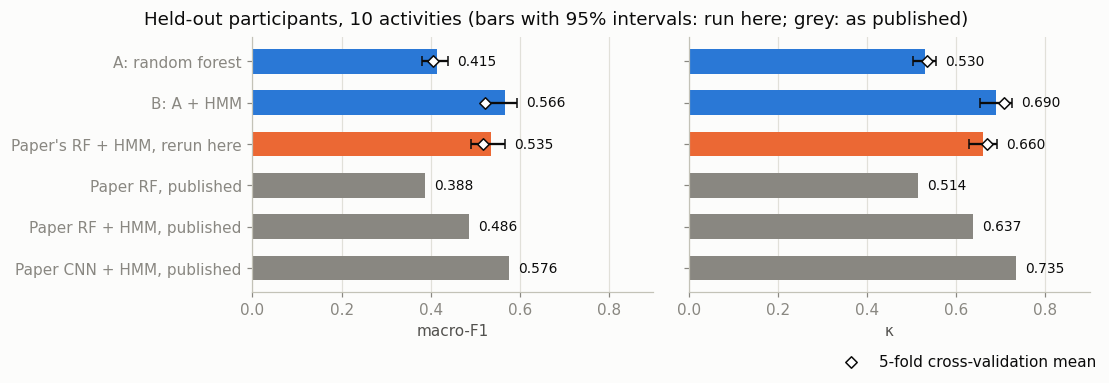

In [21]:
def plot_results():
    models = {"A: random forest": (SCORES["A"], CV.loc["A"].xs("mean", level=1), BLUE),
              "B: A + HMM": (SCORES["B"], CV.loc["B"].xs("mean", level=1), BLUE),
              "Paper's RF + HMM, rerun here": (COPY, COPY_CV.mean(), ORANGE)}
    published = {f"{name}, published": numbers for name, numbers in PAPER.items()}
    title = "Held-out participants, 10 activities (bars with 95% intervals: run here; grey: as published)"
    fig = har.plot_holdout(models, published, title)
    fig.savefig(OUT / "results.png", dpi=150)


plot_results()

The rerun of the paper's pipeline scores a little above the published numbers, and the published κ, 0.637, is inside the rerun's interval, so the rerun is a fair baseline. The paper's CNN + HMM is above B on κ; its macro-F1 is inside B's interval.

The two intervals for B and the rerun overlap, but both models predicted the same windows, so the difference can be paired: on each bootstrap draw of participants, B's score minus the rerun's. That gives +0.029 κ (95% interval 0.001 to 0.058) and +0.031 macro-F1 (−0.011 to 0.080). The lower bound for κ is so close to zero that another bootstrap seed could move it across, so this is consistent with a small gain of about 0.03 κ and does not prove one. The check matters because B's design was chosen on the CV folds over several versions, while the rerun was run once. B gets there with 300 trees against the rerun's 3,000.

B's holdout macro-F1 is 0.044 above its CV macro-F1 while its κ is lower. One activity explains that: sports, in the per-class table below.

**Figure 5.** B's holdout confusion matrix, normalised by row: where each true activity ends up.

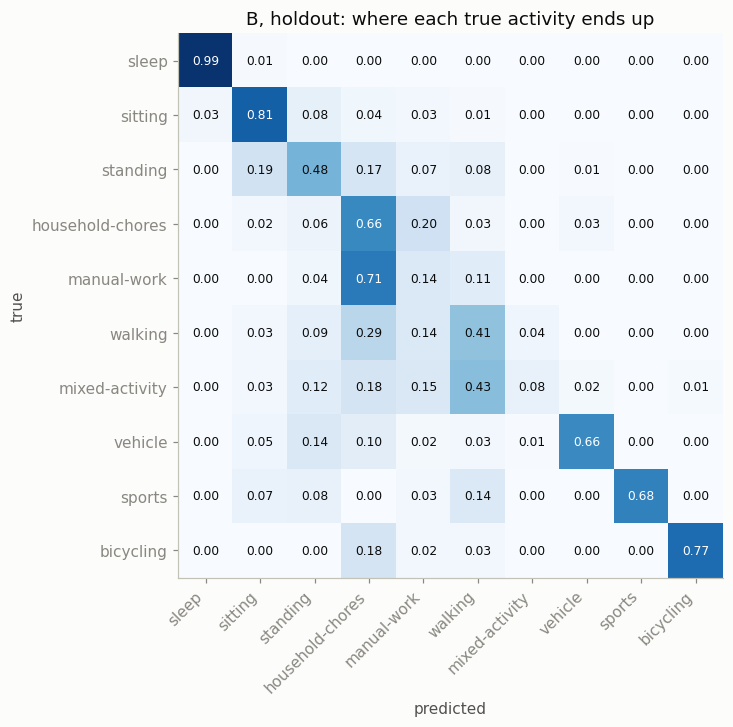

In [22]:
def plot_confusion(model="B"):
    order = [CODES.index(n) for n in CLASSES]
    cm = SCORES[model]["cm"][np.ix_(order, order)]
    cm = cm / cm.sum(axis=1, keepdims=True)
    _, ax = plt.subplots(figsize=(7.5, 6.5), layout="constrained")
    ax.imshow(cm, cmap="Blues", vmin=0, vmax=1)
    for i in range(len(order)):
        for j in range(len(order)):
            ax.text(j, i, f"{cm[i, j]:.2f}", ha="center", va="center", fontsize=8, color="white" if cm[i, j] > 0.5 else INK)
    ax.set(xticks=range(len(order)), yticks=range(len(order)), yticklabels=CLASSES, xlabel="predicted", ylabel="true",
           title=f"{model}, holdout: where each true activity ends up")
    ax.set_xticklabels(CLASSES, rotation=45, ha="right")
    ax.grid(False)


plot_confusion()

**Table 3.** F1 per activity for A and B, in cross-validation (folds pooled) and on the holdout. Pooled F1 comes from one confusion matrix over all five folds, so its mean differs from Table 2's per-fold macro-F1.

In [23]:
def per_class_f1():
    table = pd.DataFrame({f"{m} CV": metrics_from_cm(sum(CV_CM[m]))["per_class_f1"] for m in ("A", "B")}, index=CODES)
    for m in ("A", "B"):
        table[f"{m} holdout"] = pd.Series(SCORES[m]["per_class_f1"])
    return table.loc[CLASSES].round(3)


sports = Y[SCORED] == CODES.index("sports")
print(f"holdout participants with sports windows: {len(set(GROUPS[SCORED][sports]))} of {len(set(GROUPS[SCORED]))}; "
      f"sports is {sports.mean():.2%} of holdout windows")
per_class_f1()

holdout participants with sports windows: 8 of 51; sports is 0.85% of holdout windows


,A CV,B CV,A holdout,B holdout
sleep,0.892,0.970,0.908,0.980
sitting,0.681,0.861,0.687,0.873
standing,0.179,0.277,0.176,0.300
household-chores,0.447,0.596,0.416,0.531
manual-work,0.113,0.146,0.059,0.072
walking,0.313,0.422,0.331,0.426
mixed-activity,0.251,0.184,0.259,0.136
vehicle,0.454,0.792,0.423,0.733
sports,0.136,0.251,0.317,0.802
bicycling,0.692,0.820,0.570,0.810


Sports F1 is 0.80 on the holdout and 0.25 in CV. Only 8 holdout participants did any sport, so the holdout macro-F1 rests on a handful of people; the CV figure, 0.522 ± 0.033, is the safer one to quote.

Figure 5 shows where the rare activities go: B reads 71% of held-out manual-work windows as household chores and 43% of mixed-activity windows as walking; the labels themselves overlap. Smoothing helps most activities but lowers mixed-activity (Table 3).

## 4. What made the difference

The cells below rerun the five CV folds with one of B's choices swapped at a time, next to the rerun of the paper's whole pipeline. Changes are paired by fold. The emission rows swap B's probability vector for the paper's top-class emission matrix (section 2.3). "The paper's sequences" also uses its uniform prior, which only touches the first window of each sequence.

Two extra inputs for the variants: sequences that also break at every annotation gap (the leak), and an emission matrix fitted on out-of-fold forest output, which is how to avoid the out-of-bag pitfall.

In [24]:
# Labelled windows only, with a new sequence wherever one is missing.
LABELLED_SEQ = har.sequence_ids(windows["window_start"].to_numpy(), GROUPS, LABELLED)
OOF_FOLDS, OOF_TREES = 3, 50


def out_of_fold_proba(rows):
    proba = np.empty((len(rows), len(CODES)))
    folds = StratifiedGroupKFold(OOF_FOLDS, shuffle=True, random_state=SEED).split(rows, Y[rows], GROUPS[rows])
    for fit, held in folds:
        proba[held] = fit_forest(rows[fit], n_estimators=OOF_TREES).predict_proba(X[rows[held]])
    return proba

One fold's predictions for every variant, plus the share of its training windows that B's 300-tree forest leaves without out-of-bag output, measured and predicted.

In [25]:
def ablation_fold(split, paper_pred):
    train, test = split["train"], split["test"]
    labelled, scored = train[Y[train] >= 0], Y[test] >= 0
    truth = Y[labelled]
    with warnings.catch_warnings():  # the warning is counted instead: see Table 4
        warnings.filterwarnings("ignore", message="Some inputs do not have OOB scores")
        forest = fit_forest(labelled, oob_score=True)  # this fold's forest again, for its out-of-bag output
    oob, (total, count) = forest.oob_decision_function_, oob_sums(forest, X[labelled])
    assert np.allclose(oob, total / np.maximum(count, 1)[:, None]), "oob_sums does not reproduce imblearn's out-of-bag output"
    uncovered = count == 0
    split30 = {**split, "proba": fit_forest(labelled, PAPER_FEATURES).predict_proba(X[test][:, PAPER_FEATURES])}

    def matrix(output, truth):
        return decode_with(split, matrix_lik(output, truth, split["proba"]))

    return {
        "A": split["proba"][scored].argmax(axis=1),
        "A, 30 features": split30["proba"][scored].argmax(axis=1),
        "B": decode(split),
        "sequences split at annotation gaps": decode_with(split, split["proba"], LABELLED_SEQ, labelled_only=True),
        "emission matrix, fitted out-of-fold": matrix(out_of_fold_proba(labelled), truth),
        # Out-of-bag output of covered windows: what 3,000 trees give, estimated from B's 300.
        "the paper's emission matrix (estimated)": matrix(oob[~uncovered], truth[~uncovered]),
        "emission matrix from 300-tree out-of-bag output": matrix(oob, truth),
        "30 features": decode(split30),
        "the paper's sequences": decode_with(split, split["proba"], PARTICIPANT_SEQ, labelled_only=True, uniform_prior=True),
        "the paper's whole pipeline": paper_pred,
    }, uncovered_share(count, truth), expected_uncovered(truth, N_TREES)


def ablation():
    folds = [ablation_fold(split, pred) for split, (pred, _) in zip(CV_SPLITS, PAPER_CV)]
    scores = pd.DataFrame([{"variant": name, "fold": fold, **metrics_from_cm(confusion(rows, pred))}
                           for fold, ((rows, _), (preds, _, _)) in enumerate(zip(CV_PRED, folds))
                           for name, pred in preds.items()]).set_index(["variant", "fold"])
    uncovered = pd.DataFrame({f"{N_TREES} trees": np.mean([u for _, u, _ in folds], axis=0),
                              f"{N_TREES} trees, by the rule": np.mean([e for _, _, e in folds], axis=0),
                              f"{PAPER_TREES:,} trees": np.mean([u for _, u in PAPER_CV], axis=0)}, index=CODES)
    return scores, uncovered.loc[CLASSES]

**Table 4.** Share of training windows that get no out-of-bag output, per activity and mean over folds: measured with B's 300 trees, predicted by the rule, and measured with the paper's 3,000.

In [26]:
ABLATION, UNCOVERED = ablation()
UNCOVERED.T.round(3)

,sleep,sitting,standing,household-chores,manual-work,walking,mixed-activity,vehicle,sports,bicycling
300 trees,0.290,0.289,0.0,0.002,0.0,0.002,0.0,0.0,0.0,0.0
"300 trees, by the rule",0.292,0.290,0.0,0.002,0.0,0.002,0.0,0.0,0.0,0.0
"3,000 trees",0.000,0.000,0.0,0.000,0.0,0.000,0.0,0.0,0.0,0.0


**Table 5.** Each variant on the five CV folds: mean scores, and the change against B as mean ± standard error of the per-fold differences.

In [27]:
def ablation_table():
    scores = ABLATION[list(SHOWN)]
    change = scores.sub(scores.loc["B"], level="fold").groupby("variant", sort=False)
    table = scores.groupby("variant", sort=False).mean().round(3).rename(columns=SHOWN)
    for m, name in SHOWN.items():
        table[f"{name} against B"] = [f"{mean:+.3f} ± {sem:.3f}" for mean, sem in zip(change[m].mean(), change[m].sem())]
    return table


ablation_table()

,macro-F1,κ,macro-F1 against B,κ against B
variant,,,,
A,0.406,0.535,-0.115 ± 0.012,-0.173 ± 0.009
"A, 30 features",0.375,0.488,-0.147 ± 0.015,-0.221 ± 0.008
B,0.522,0.708,+0.000 ± 0.000,+0.000 ± 0.000
sequences split at annotation gaps,0.543,0.724,+0.021 ± 0.005,+0.015 ± 0.004
"emission matrix, fitted out-of-fold",0.495,0.706,-0.027 ± 0.015,-0.002 ± 0.010
the paper's emission matrix (estimated),0.521,0.707,-0.001 ± 0.015,-0.002 ± 0.010
emission matrix from 300-tree out-of-bag output,0.504,0.633,-0.018 ± 0.018,-0.075 ± 0.024
30 features,0.559,0.703,+0.037 ± 0.016,-0.005 ± 0.005
the paper's sequences,0.529,0.697,+0.007 ± 0.007,-0.012 ± 0.005


**Figure 6.** The changes from Table 5 that separate B from the paper's pipeline, and the two pitfalls.

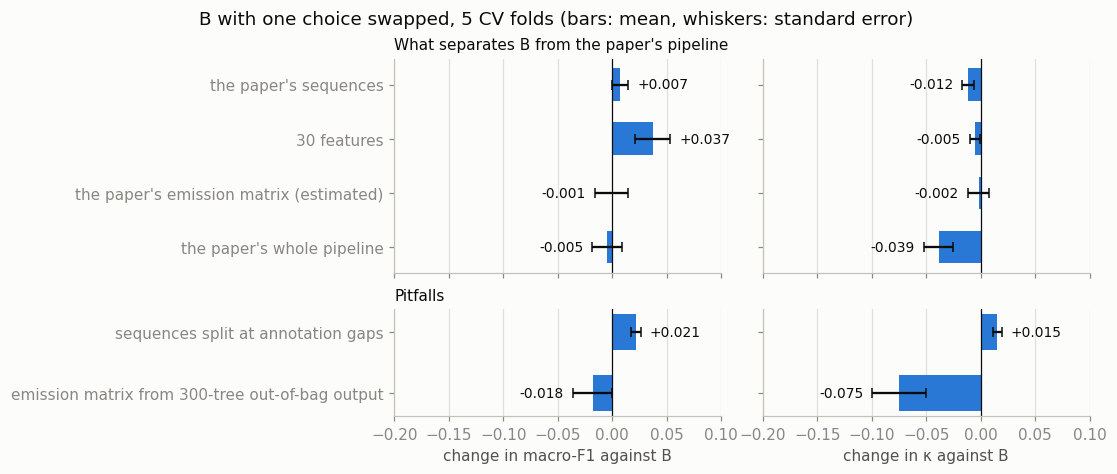

In [28]:
CHART_ROWS = {"What separates B from the paper's pipeline": ["the paper's sequences", "30 features",
                                                             "the paper's emission matrix (estimated)",
                                                             "the paper's whole pipeline"],
              "Pitfalls": ["sequences split at annotation gaps", "emission matrix from 300-tree out-of-bag output"]}


def plot_ablation():
    fig, axes = plt.subplots(2, 2, figsize=(10, 4.2), sharex=True, sharey="row", layout="constrained",
                             height_ratios=[len(rows) for rows in CHART_ROWS.values()])
    for row, (title, variants) in zip(axes, CHART_ROWS.items()):
        for ax, metric in zip(row, SHOWN):
            change = pd.DataFrame({v: ABLATION.loc[v, metric] - ABLATION.loc["B", metric] for v in variants})
            ax.barh(variants, change.mean(), xerr=change.sem(), color=BLUE, height=0.6, ecolor=INK, capsize=3)
            har.label_bars(ax, change.mean(), change.sem(), "+.3f")
            ax.axvline(0, color=INK, lw=0.8)
            ax.set(xlim=(-0.2, 0.1))
            ax.grid(axis="y", visible=False)
        row[0].invert_yaxis()
        row[0].set_title(title, loc="left", fontsize=10)
    for ax, name in zip(axes[-1], SHOWN.values()):
        ax.set_xlabel(f"change in {name} against B")
    fig.suptitle("B with one choice swapped, 5 CV folds (bars: mean, whiskers: standard error)")


plot_ablation()

**Table 6.** Change in F1 per activity with 30 features against B, mean over the five CV folds: is the 30-feature gain one activity?

In [29]:
by_class = pd.DataFrame(ABLATION["per_class_f1"].tolist(), index=ABLATION.index, columns=CODES)
(by_class.loc["30 features"] - by_class.loc["B"]).mean().sort_values().round(3)

standing           -0.037
sitting            -0.021
sleep              -0.008
vehicle            -0.007
household-chores   -0.006
bicycling           0.037
walking             0.039
mixed-activity      0.054
manual-work         0.094
sports              0.226
dtype: float64

- **B against the paper's pipeline: +0.039 κ (standard error 0.013), and the same macro-F1 (+0.005, standard error 0.014).** No single choice tested explains the gain. Each moves κ by 0.002 to 0.012 (the paper's emission matrix 0.002, its 30 features 0.005, its sequences 0.012), and together they account for about half of it; the rest is interaction between the choices or fold noise, since the gap between the sum and the whole is about 1.5 standard errors. One difference was never swapped: the paper's 3,000 trees against B's 300, so tree count is also a candidate for the unexplained half.
- **Pitfall: splitting sequences at annotation gaps leaks.** The gaps tell the HMM where an activity starts and ends, worth 0.021 macro-F1 that a deployed model would not get. B decodes every window.
- **Pitfall: out-of-bag output from too few trees for the class ratio.** imblearn counts a window as out-of-bag for a tree only if it is in that tree's undersampled pool and the tree's bootstrap missed it, so a majority-class window is out-of-bag for about trees × (smallest class ÷ its class) × 0.37 trees. Here the ratio is about 1/85, so 300 trees give about one such tree per sleep or sitting window and 29% of them get none; the rule predicts the measured shares above, and about 800 trees would be needed to get below 3%. A window with none keeps a row of zeros, which shrinks those two rows of the emission matrix and costs 0.075 κ. imblearn warns ("Some inputs do not have OOB scores"), but the warning says neither how many windows are affected nor that their rows become zeros, and it is easy to filter out; the ablation cell above filters it. Leaving the uncovered windows out removes the loss (−0.002 κ), as does fitting the matrix out-of-fold; with the paper's 3,000 trees every window is covered, so its out-of-bag fit is sound.
- **Open: 30 features beat 39 for B on macro-F1 (+0.037, standard error 0.016), with κ unchanged.** It is a trade: sports gains 0.23 F1 and manual-work 0.09, while standing loses 0.04 and sitting 0.02. For A alone the nine orientation features help (+0.03 macro-F1). B keeps 39 because the holdout was already scored with them; switching now would mean scoring it a third time.

## 5. Saved results

Every score goes to `outputs/results.json`, which part 2 reads.

In [30]:
def save_results():
    change = ABLATION[list(SHOWN)].sub(ABLATION.loc["B", list(SHOWN)], level="fold")
    results = {"config": {"seed": SEED, "n_folds": N_FOLDS, "n_boot": N_BOOT, "n_trees": N_TREES, "winsec": F.WINSEC,
                          "n_features": len(F.FEATURE_NAMES), "scheme": SCHEME},
               "windows": COUNTS.to_dict(), "paper": {"10-class": PAPER},
               "paper_copy_10-class": {"n_trees": PAPER_TREES, "n_features": len(PAPER_FEATURES),
                                       "cv": COPY_CV.agg(["mean", "std"]).to_dict(),
                                       "holdout": {m: COPY[m] for m in SHOWN}, "holdout_per_class_f1": COPY["per_class_f1"],
                                       "holdout_B_minus_copy": GAIN},
               "ablation_10-class_cv": {
                   "mean": ABLATION[list(SHOWN)].groupby("variant", sort=False).mean().to_dict("index"),
                   "change_against_B_mean": change.groupby("variant", sort=False).mean().to_dict("index"),
                   "change_against_B_std": change.groupby("variant", sort=False).std().to_dict("index")},
               "tasks": {"10-class": {model: {"cv": {m: dict(zip(("mean", "std"), CV.loc[model, m])) for m in SHOWN},
                                              "holdout": {m: SCORES[model][m] for m in SHOWN},
                                              "holdout_per_class_f1": SCORES[model]["per_class_f1"]}
                                      for model in ("Dummy", "A", "B")}}}
    (OUT / "results.json").write_text(json.dumps(results, indent=2))


save_results()
print(f"run time: {(perf_counter() - T0) / 60:.1f} min")

run time: 6.1 min


## 6. Limitations and next steps

- **Label noise.** Labels come from camera frames 20-40 s apart plus sleep diaries, and the paper says annotators sometimes guessed.
- **One cohort.** All 151 participants were recruited around Oxford; nothing here shows the model transfers.
- **Rare activities.** Sports, manual-work and mixed-activity have few windows from few people, and macro-F1 weights each like sleep.
- **A small edge, and a design chosen on the same folds.** B's gain over the paper's pipeline is 0.04 κ on five folds, with no gain in macro-F1. B's design was chosen on those folds over several versions and the rerun was run once, which favours B slightly in CV; the paired holdout difference (+0.029 κ, interval 0.001 to 0.058) is the check against that, and its lower bound is barely above zero.
- **Holdout scored twice,** as noted under Results.

Part 2, [`capture24_new_model.ipynb`](capture24_new_model.ipynb), looks at where B's errors are and replaces the forest with a pretrained encoder.

## References

**Data and benchmark**

- Chan, S., Yuan, H., Tong, C., Acquah, A., Schonfeldt, A., Gershuny, J., & Doherty, A. (2024). CAPTURE-24: A large dataset of wrist-worn activity tracker data collected in the wild for human activity recognition. *Scientific Data*, 11, 1135. https://doi.org/10.1038/s41597-024-03960-3 (used for: the dataset paper and the published baselines)
- Chan Chang, S., Walmsley, R., Gershuny, J., Harms, T., Thomas, E., Milton, K., Kelly, P., Foster, C., Wong, A., Gray, N., Haque, S., Hollowell, S., & Doherty, A. (2021). *Capture-24: Activity tracker dataset for human activity recognition* [Data set]. University of Oxford. https://doi.org/10.5287/bodleian:NGx0JOMP5 (used for: the data, CC BY 4.0)
- OxWearables. *capture24*: benchmark code and feature list for CAPTURE-24. https://github.com/OxWearables/capture24 (used for: `prepare_data.py`, the feature list, and the paper's pipeline in `rf.py`, `classifier.py`, `hmm.py` and `eval.py`)
- Willetts, M., Hollowell, S., Aslett, L., Holmes, C., & Doherty, A. (2018). Statistical machine learning of sleep and physical activity phenotypes from sensor data in 96,220 UK Biobank participants. *Scientific Reports*, 8, 7961. https://doi.org/10.1038/s41598-018-26174-1 (used for: the 10-class scheme, `WillettsSpecific2018`, and the balanced forest + HMM approach)

**Methods**

- Breiman, L. (2001). Random forests. *Machine Learning*, 45(1), 5-32. https://doi.org/10.1023/A:1010933404324 (used for: random forests and out-of-bag estimates)
- Chen, C., Liaw, A., & Breiman, L. (2004). *Using random forest to learn imbalanced data* (Technical Report 666). Department of Statistics, University of California, Berkeley. https://statistics.berkeley.edu/sites/default/files/tech-reports/666.pdf (used for: the balanced random forest)
- Rabiner, L. R. (1989). A tutorial on hidden Markov models and selected applications in speech recognition. *Proceedings of the IEEE*, 77(2), 257-286. https://doi.org/10.1109/5.18626 (used for: hidden Markov models)
- Viterbi, A. J. (1967). Error bounds for convolutional codes and an asymptotically optimum decoding algorithm. *IEEE Transactions on Information Theory*, 13(2), 260-269. https://doi.org/10.1109/TIT.1967.1054010 (used for: the Viterbi algorithm)
- Cohen, J. (1960). A coefficient of agreement for nominal scales. *Educational and Psychological Measurement*, 20(1), 37-46. https://doi.org/10.1177/001316446002000104 (used for: κ)
- Efron, B., & Tibshirani, R. J. (1993). *An introduction to the bootstrap*. Chapman & Hall. (used for: percentile bootstrap intervals)
- Field, C. A., & Welsh, A. H. (2007). Bootstrapping clustered data. *Journal of the Royal Statistical Society: Series B*, 69(3), 369-390. https://doi.org/10.1111/j.1467-9868.2007.00593.x (used for: resampling whole participants, the clusters, in the bootstrap)

**Software**

- Pedregosa, F., Varoquaux, G., Gramfort, A., Michel, V., Thirion, B., Grisel, O., Blondel, M., Prettenhofer, P., Weiss, R., Dubourg, V., Vanderplas, J., Passos, A., Cournapeau, D., Brucher, M., Perrot, M., & Duchesnay, É. (2011). Scikit-learn: Machine learning in Python. *Journal of Machine Learning Research*, 12, 2825-2830.
- Lemaître, G., Nogueira, F., & Aridas, C. K. (2017). Imbalanced-learn: A Python toolbox to tackle the curse of imbalanced datasets in machine learning. *Journal of Machine Learning Research*, 18(17), 1-5. (used for: `BalancedRandomForestClassifier`)